Author:  
Manuel Eugenio Morocho Cayamcela, PhD

# **Unsupervised Learning**
## Mall Customer Clustering with KMeans

### **Introduction**

This activity introduces clustering using the `mall_customers.csv` dataset, which contains information about shopping mall customers, including a variable that represents their spending behavior.

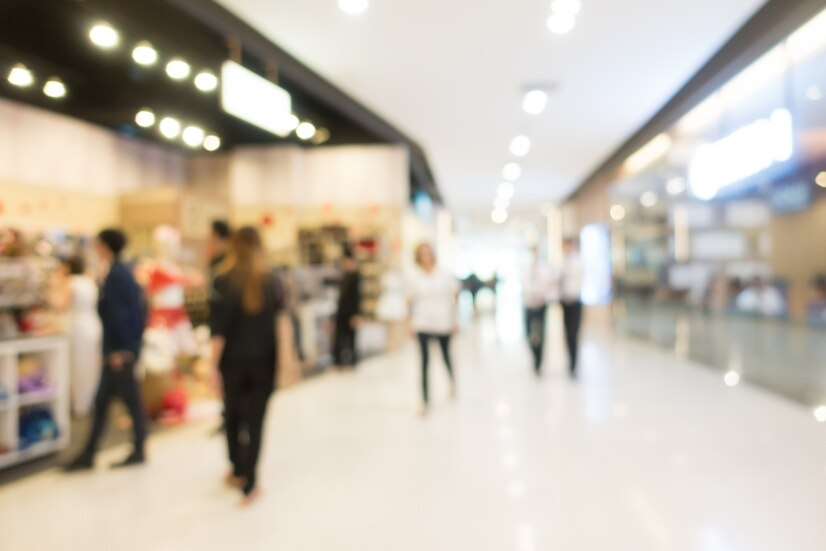

## Learning goals
Segment customers using income and spending score, explain the effect of scaling, interpret centroids and group profiles, justify a choice of k, and assign a new customer using the same preprocessing.

Run the guided sections in order. The final assignment contains commented placeholders for you to complete.

### Understand the variables
- **CustomerID** identifies a customer. Its numerical differences do not describe customer similarity.
- **Gender** and **Age** describe customers and remain available for exploration.
- **Annual Income (k$)** is annual income in thousands of dollars.
- **Spending Score (1–100)** is a provided score describing spending behavior. The CSV does not document its calculation. Frequency and purchase value are possible ingredients of business scoring systems, but their use in this dataset is unverified.

We use income and spending score for clustering. A group is defined by similarity in these two selected characteristics.

### Import packages

In [1]:
# Run if dependencies are missing.
# %pip install scikit-learn pandas numpy matplotlib seaborn ydata-profiling ipywidgets "setuptools<81"

In [2]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score
plt.rcParams.update({'figure.figsize': (8,5), 'font.size': 11})


### Load and inspect the dataset
The embedded copy comes from the course repository and permits offline data loading. [Source CSV](https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/mall_customers.csv).

In [3]:
CSV_DATA = 'CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)\n1,Male,19,15,39\n2,Male,21,15,81\n3,Female,20,16,6\n4,Female,23,16,77\n5,Female,31,17,40\n6,Female,22,17,76\n7,Female,35,18,6\n8,Female,23,18,94\n9,Male,64,19,3\n10,Female,30,19,72\n11,Male,67,19,14\n12,Female,35,19,99\n13,Female,58,20,15\n14,Female,24,20,77\n15,Male,37,20,13\n16,Male,22,20,79\n17,Female,35,21,35\n18,Male,20,21,66\n19,Male,52,23,29\n20,Female,35,23,98\n21,Male,35,24,35\n22,Male,25,24,73\n23,Female,46,25,5\n24,Male,31,25,73\n25,Female,54,28,14\n26,Male,29,28,82\n27,Female,45,28,32\n28,Male,35,28,61\n29,Female,40,29,31\n30,Female,23,29,87\n31,Male,60,30,4\n32,Female,21,30,73\n33,Male,53,33,4\n34,Male,18,33,92\n35,Female,49,33,14\n36,Female,21,33,81\n37,Female,42,34,17\n38,Female,30,34,73\n39,Female,36,37,26\n40,Female,20,37,75\n41,Female,65,38,35\n42,Male,24,38,92\n43,Male,48,39,36\n44,Female,31,39,61\n45,Female,49,39,28\n46,Female,24,39,65\n47,Female,50,40,55\n48,Female,27,40,47\n49,Female,29,40,42\n50,Female,31,40,42\n51,Female,49,42,52\n52,Male,33,42,60\n53,Female,31,43,54\n54,Male,59,43,60\n55,Female,50,43,45\n56,Male,47,43,41\n57,Female,51,44,50\n58,Male,69,44,46\n59,Female,27,46,51\n60,Male,53,46,46\n61,Male,70,46,56\n62,Male,19,46,55\n63,Female,67,47,52\n64,Female,54,47,59\n65,Male,63,48,51\n66,Male,18,48,59\n67,Female,43,48,50\n68,Female,68,48,48\n69,Male,19,48,59\n70,Female,32,48,47\n71,Male,70,49,55\n72,Female,47,49,42\n73,Female,60,50,49\n74,Female,60,50,56\n75,Male,59,54,47\n76,Male,26,54,54\n77,Female,45,54,53\n78,Male,40,54,48\n79,Female,23,54,52\n80,Female,49,54,42\n81,Male,57,54,51\n82,Male,38,54,55\n83,Male,67,54,41\n84,Female,46,54,44\n85,Female,21,54,57\n86,Male,48,54,46\n87,Female,55,57,58\n88,Female,22,57,55\n89,Female,34,58,60\n90,Female,50,58,46\n91,Female,68,59,55\n92,Male,18,59,41\n93,Male,48,60,49\n94,Female,40,60,40\n95,Female,32,60,42\n96,Male,24,60,52\n97,Female,47,60,47\n98,Female,27,60,50\n99,Male,48,61,42\n100,Male,20,61,49\n101,Female,23,62,41\n102,Female,49,62,48\n103,Male,67,62,59\n104,Male,26,62,55\n105,Male,49,62,56\n106,Female,21,62,42\n107,Female,66,63,50\n108,Male,54,63,46\n109,Male,68,63,43\n110,Male,66,63,48\n111,Male,65,63,52\n112,Female,19,63,54\n113,Female,38,64,42\n114,Male,19,64,46\n115,Female,18,65,48\n116,Female,19,65,50\n117,Female,63,65,43\n118,Female,49,65,59\n119,Female,51,67,43\n120,Female,50,67,57\n121,Male,27,67,56\n122,Female,38,67,40\n123,Female,40,69,58\n124,Male,39,69,91\n125,Female,23,70,29\n126,Female,31,70,77\n127,Male,43,71,35\n128,Male,40,71,95\n129,Male,59,71,11\n130,Male,38,71,75\n131,Male,47,71,9\n132,Male,39,71,75\n133,Female,25,72,34\n134,Female,31,72,71\n135,Male,20,73,5\n136,Female,29,73,88\n137,Female,44,73,7\n138,Male,32,73,73\n139,Male,19,74,10\n140,Female,35,74,72\n141,Female,57,75,5\n142,Male,32,75,93\n143,Female,28,76,40\n144,Female,32,76,87\n145,Male,25,77,12\n146,Male,28,77,97\n147,Male,48,77,36\n148,Female,32,77,74\n149,Female,34,78,22\n150,Male,34,78,90\n151,Male,43,78,17\n152,Male,39,78,88\n153,Female,44,78,20\n154,Female,38,78,76\n155,Female,47,78,16\n156,Female,27,78,89\n157,Male,37,78,1\n158,Female,30,78,78\n159,Male,34,78,1\n160,Female,30,78,73\n161,Female,56,79,35\n162,Female,29,79,83\n163,Male,19,81,5\n164,Female,31,81,93\n165,Male,50,85,26\n166,Female,36,85,75\n167,Male,42,86,20\n168,Female,33,86,95\n169,Female,36,87,27\n170,Male,32,87,63\n171,Male,40,87,13\n172,Male,28,87,75\n173,Male,36,87,10\n174,Male,36,87,92\n175,Female,52,88,13\n176,Female,30,88,86\n177,Male,58,88,15\n178,Male,27,88,69\n179,Male,59,93,14\n180,Male,35,93,90\n181,Female,37,97,32\n182,Female,32,97,86\n183,Male,46,98,15\n184,Female,29,98,88\n185,Female,41,99,39\n186,Male,30,99,97\n187,Female,54,101,24\n188,Male,28,101,68\n189,Female,41,103,17\n190,Female,36,103,85\n191,Female,34,103,23\n192,Female,32,103,69\n193,Male,33,113,8\n194,Female,38,113,91\n195,Female,47,120,16\n196,Female,35,120,79\n197,Female,45,126,28\n198,Male,32,126,74\n199,Male,32,137,18\n200,Male,30,137,83\n'
clients = pd.read_csv(io.StringIO(CSV_DATA))
display(clients.head(10))
display(clients.describe())
display(clients.isna().sum().to_frame("Missing values"))

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


,Missing values
CustomerID,0
Gender,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


### Explore with the Profiler
The report includes distributions, missing values and relationships. Keep Gender as a categorical variable. CustomerID is excluded from the profiling report because its numerical distances have no behavioral meaning.

In [4]:
from ydata_profiling import ProfileReport
profile_data = clients.drop(columns='CustomerID').copy()
data_profile = ProfileReport(profile_data, title='Customer Data Profile Report', explorative=True)


In [5]:
data_profile.to_notebook_iframe()

None

In [6]:
data_profile.to_file('client_profile_report.html')

### Select income and spending score
Before fitting, predict how many groups you see. Which customers seem similar? Which differences could matter for a marketing decision?

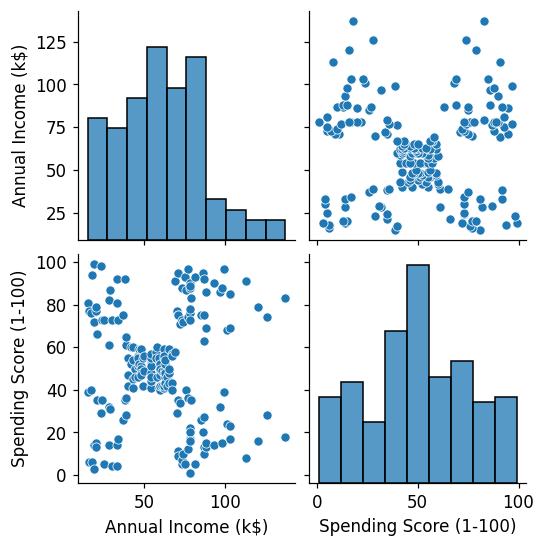

In [7]:
features = ['Annual Income (k$)', 'Spending Score (1-100)']
income_spending = clients[features].copy()
assert not income_spending.isna().any().any()
sns.pairplot(income_spending)
plt.show()


### Standardize the distance calculation
K-Means minimizes the sum of squared distances to assigned centroids
$$J=\sum_i\|z_i-\mu_{c_i}\|^2.$$
Income and spending score have different meanings and units. Standardization gives each variable variance one in the representation used for distances
$$z_{ij}=\frac{x_{ij}-\bar x_j}{s_j}.$$
`StandardScaler` uses a standard deviation calculated with divisor n. Scaling is a modeling choice that determines the relative influence of the inputs. We display results in original units so the profiles remain interpretable.

In [8]:
preview_scaler = StandardScaler()
scaled_preview = preview_scaler.fit_transform(income_spending)
display(pd.DataFrame({'Mean':income_spending.mean(), 'Standard deviation':income_spending.std(ddof=0),
                      'First customer z':scaled_preview[0]}))
assert np.allclose(scaled_preview.mean(axis=0),0)
assert np.allclose(scaled_preview.var(axis=0),1)


,Mean,Standard deviation,First customer z
Annual Income (k$),60.56,26.198977,-1.738999
Spending Score (1-100),50.20,25.758882,-0.434801


### Fit an initial two-group model
The pipeline fits the scaler, transforms the data and fits K-Means. It reuses the fitted scaler when predicting new customers. We use 20 initializations and a fixed random seed. The initial k=2 is a teaching choice to explore before selecting a final value.

In [9]:
kmeans_model = Pipeline([
    ('scaler', StandardScaler()),
    ('kmeans', KMeans(n_clusters=2, n_init=20, random_state=75))
])
kmeans_model.fit(income_spending)
income_spending_cluster = income_spending.copy()
income_spending_cluster['Cluster'] = kmeans_model.named_steps['kmeans'].labels_
centers = kmeans_model.named_steps['scaler'].inverse_transform(
    kmeans_model.named_steps['kmeans'].cluster_centers_)


### Show the customers and centroids
A centroid is the mean of its group in the fitted representation. Red crosses below are transformed back to original units. Cluster numbers are arbitrary identifiers.

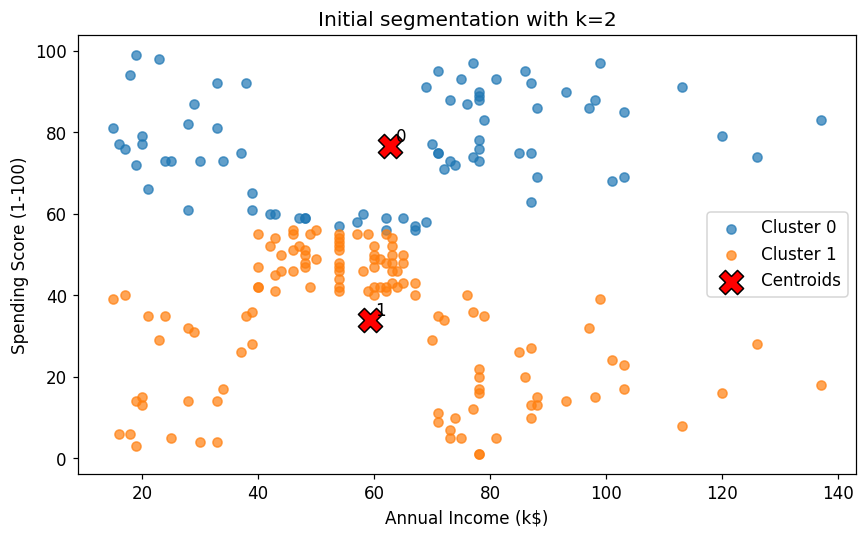

In [10]:
def plot_segments(model, title, new_customer=None):
    labels = model.named_steps['kmeans'].labels_
    centers = model.named_steps['scaler'].inverse_transform(model.named_steps['kmeans'].cluster_centers_)
    fig, ax = plt.subplots()
    for group in np.unique(labels):
        selected = labels == group
        ax.scatter(income_spending.loc[selected,features[0]],income_spending.loc[selected,features[1]],
                   label=f'Cluster {group}',alpha=.7)
    ax.scatter(centers[:,0],centers[:,1],marker='X',s=250,c='red',edgecolor='black',label='Centroids')
    for group, center in enumerate(centers): ax.annotate(str(group),center+1)
    if new_customer is not None:
        ax.scatter(new_customer.iloc[:,0],new_customer.iloc[:,1],marker='*',s=300,c='gold',edgecolor='black',label='New customer')
    ax.set(xlabel=features[0],ylabel=features[1],title=title)
    ax.legend(); plt.tight_layout(); plt.show()
plot_segments(kmeans_model,'Initial segmentation with k=2')


### Describe the segments with evidence
Use group sizes and summary values to support a segment name and recommendation. Income and score retain their original units in this table.

In [11]:
profiles = income_spending_cluster.groupby('Cluster').agg(
    Customers=(features[0],'size'),
    Mean_income=(features[0],'mean'), Median_income=(features[0],'median'),
    Mean_score=(features[1],'mean'), Median_score=(features[1],'median'))
display(profiles.round(2))
print('Inertia in standardized units:',kmeans_model.named_steps['kmeans'].inertia_)


,Customers,Mean_income,Median_income,Mean_score,Median_score
Cluster,,,,,
0,76,62.75,69.5,76.67,75.5
1,124,59.22,60.0,33.98,40.0


Inertia in standardized units: 269.69101219276405


### Compare another level of detail
Fit k=5 with the same preprocessing. Describe what changed relative to k=2. Consider whether the finer groups support different business actions.

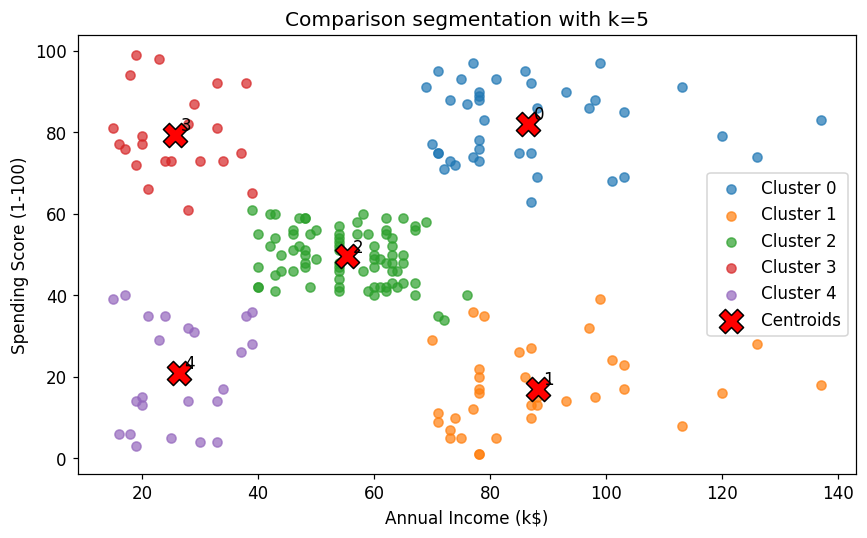

In [12]:
comparison_model = Pipeline([
    ('scaler',StandardScaler()),
    ('kmeans',KMeans(n_clusters=5,n_init=20,random_state=75))
]).fit(income_spending)
plot_segments(comparison_model,'Comparison segmentation with k=5')


### Assign a new customer
The record uses the same feature names and units as the training data. The pipeline applies the fitted scaling before assigning the nearest centroid. The output is a segment assignment based on the supplied income and score.

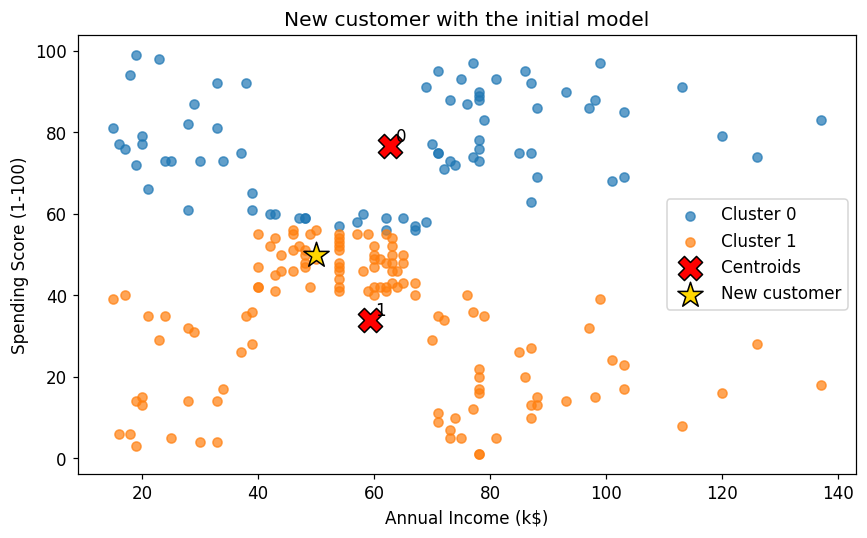

,Customers,Mean_income,Median_income,Mean_score,Median_score
Cluster,,,,,
1,124,59.217742,60.0,33.975806,40.0


Assigned cluster: 1


In [13]:
new_customer = pd.DataFrame([[50,50]],columns=features)
new_cluster = kmeans_model.predict(new_customer)
print('Assigned cluster:',new_cluster[0])
plot_segments(kmeans_model,'New customer with the initial model',new_customer)
display(profiles.loc[[new_cluster[0]]])


### Prepare to choose k
Inertia decreases as model flexibility increases. The elbow suggests a point of diminishing improvement. Silhouette combines within-group cohesion and separation from other groups, and is defined when there are at least two groups and fewer groups than observations.

Calculate both across candidate values of k in the assignment. Interpret them alongside group sizes, profiles and the intended business action. Compare models using the same inputs and scaling.

For a fitted pipeline, obtain the labels with `model.named_steps['kmeans'].labels_`, inertia with `model.named_steps['kmeans'].inertia_`, and standardized inputs with `model.named_steps['scaler'].transform(income_spending)`.

The silhouette calculation is `silhouette_score(standardized_inputs, labels)`.

### **Group Assignment**

Complete **one** of the two options below. Each option is graded independently out of **10 points**. Both options use the elbow method: fit KMeans for a range of $k$ values and plot the inertia (the sum of squared distances from data points to their assigned cluster centers). The elbow—the point where the decrease in inertia begins to slow—can help you choose $k$.

---

Also calculate silhouette for candidate k values of at least 2 and discuss whether it supports your choice. Include this evidence within the existing model-selection marks. Keep the total at 10 points.

### **Option 1: Mall Customers Dataset (10 points)**

**Code (4 points)**

- **Elbow method (2 points):** Fit KMeans models for a reasonable range of $k$ values and record each model's inertia.
- **Plot and model selection (2 points):** Produce a clearly labeled elbow plot, select a value of $k$, and briefly justify the choice. Refit `kmeans_model` as a StandardScaler + KMeans pipeline with the selected value before answering the questions. Recreate the cluster plot, centroid plot and profile table from that final model.

In [14]:
# Write your code here to calculate inertia for a range of k values, plot the elbow curve,
# select k, and refit kmeans_model using the selected value.

**Analysis questions (6 points)**

***1. Which customer group would you focus on? (2 points)***

Identify the cluster and describe its profile using its customer count and at least two numerical profile values to support your choice.

**Your response:** ________________________________________

***2. What actionable strategies could we recommend to increase spending at the shopping mall? (2 points)***

Recommend a specific strategy, identify the cluster it targets, and support the recommendation with its customer count and at least two numerical profile values.

**Your response:** ________________________________________

***3. Which group would a new customer with an annual income (k$) of 110 and a spending score of 21 belong to? (2 points)***

Use the final fitted model in the code cell below, then explain the predicted assignment using the cluster results.

In [15]:
# Create a record with the new customer's values and assign it to a cluster using the trained KMeans model.
# new_client = pd.DataFrame([[___, ___]], columns=features)
# Use the KMeans model's predict method to predict the cluster of the new customer.
# new_cluster = kmeans_model.predict(new_client)

**Your explanation:** _______________________________________

**Rubric (10 points):** 
- Elbow method and inertia values (2); 
- Elbow plot, selected $k$, and justification (2); 
- Priority customer group and evidence (2); 
- Actionable spending strategy supported by a cluster profile (2); 
- New-customer prediction using the final model and explanation (2).

---

### **Option 2: New Dataset (10 points)**

**Dataset and feature selection (3 points)**

- **Dataset and source (1 point):** Use another dataset and identify its source.
- **Variable description (1 point):** Describe every variable in the dataset.
- **Feature selection (1 point):** Explain which variables you use for clustering and why they are appropriate.

**Dataset and source:** ________________________________________

**Variable descriptions:** _____________________________________

**Selected features and justification:** ______________________________

**KMeans modeling code (4 points)**

- **Elbow method and choice of $k$ (2 points):** Apply the elbow method to a range of values, show the plot, and state the selected $k$.
- **Fit and visualization (2 points):** Fit KMeans with the selected $k$ and visualize the resulting clusters.

Use the code cell below for your analysis. Keep the selected features and any preprocessing consistent when fitting and visualizing the clusters.

Use a consistent preprocessing pipeline and report segment sizes and profiles. If you use more than two features, state which variables or projection your plot displays.

In [16]:
# Write your new-dataset KMeans analysis here:
# 1. Calculate inertia for a range of k values and plot the elbow curve.
# 2. Select k, fit KMeans, and visualize the resulting clusters.

**Findings and interpretation (3 points)**

***1. Which cluster would you prioritize for action or further study? Describe its profile using the model variables and support your choice with the results. (1 point)***

**Your response:** ________________________________________

***2. What practical, actionable recommendation would you make based on the cluster profiles? Identify the cluster it targets and explain how the results support it. (1 point)***

**Your response:** ________________________________________

***3. Create a plausible new observation using the selected features and the same preprocessing and feature order. Which cluster does your fitted model predict, and how do the results support the assignment? Include your prediction code. (1 point)***

In [17]:
# Create and preprocess one new observation, then predict its cluster.
# Keep its feature order consistent with the data used to fit the model.

**Your explanation:** _______________________________________

**Rubric (10 points):** 
- Dataset and source (1); 
- Variable descriptions (1); 
- Feature selection and justification (1); 
- Elbow method, plot, and selected $k$ (2); 
- KMeans fit and cluster visualization (2); 
- Three evidence-based findings (1 each).